# Week 4 – Day 1: Statistics

## Practical Task 1 – Calculate Descriptive Statistics

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("Downloads/Salary_Dataset_with_Extra_Features.csv")

print("Dataset loaded successfully!")

print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (22770, 8)


,Rating,Company Name,Job Title,Salary,Salaries Reported,Location,Employment Status,Job Roles
0,3.8,Sasken,Android Developer,400000,3,Bangalore,Full Time,Android
1,4.5,Advanced Millennium Technologies,Android Developer,400000,3,Bangalore,Full Time,Android
2,4.0,Unacademy,Android Developer,1000000,3,Bangalore,Full Time,Android
3,3.8,SnapBizz Cloudtech,Android Developer,300000,3,Bangalore,Full Time,Android
4,4.4,Appoids Tech Solutions,Android Developer,600000,3,Bangalore,Full Time,Android


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22770 entries, 0 to 22769
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Rating             22770 non-null  float64
 1   Company Name       22769 non-null  object 
 2   Job Title          22770 non-null  object 
 3   Salary             22770 non-null  int64  
 4   Salaries Reported  22770 non-null  int64  
 5   Location           22770 non-null  object 
 6   Employment Status  22770 non-null  object 
 7   Job Roles          22770 non-null  object 
dtypes: float64(1), int64(2), object(5)
memory usage: 1.4+ MB


In [5]:
df.describe(include='all')

,Rating,Company Name,Job Title,Salary,Salaries Reported,Location,Employment Status,Job Roles
count,22770.000000,22769,22770,2.277000e+04,22770.000000,22770,22770,22770
unique,NaN,11260,1080,NaN,NaN,10,4,11
top,NaN,Tata Consultancy Services,Software Development Engineer,NaN,NaN,Bangalore,Full Time,SDE
freq,NaN,271,2351,NaN,NaN,8264,20083,8183
mean,3.918213,NaN,NaN,6.953872e+05,1.855775,NaN,NaN,NaN
std,0.519675,NaN,NaN,8.843990e+05,6.823668,NaN,NaN,NaN
min,1.000000,NaN,NaN,2.112000e+03,1.000000,NaN,NaN,NaN
25%,3.700000,NaN,NaN,3.000000e+05,1.000000,NaN,NaN,NaN
50%,3.900000,NaN,NaN,5.000000e+05,1.000000,NaN,NaN,NaN
75%,4.200000,NaN,NaN,9.000000e+05,1.000000,NaN,NaN,NaN


In [6]:
df['Salary'] = (
    df['Salary']
    .astype(str)
    .str.replace(',', '', regex=False)
    .str.replace('₹', '', regex=False)
    .str.replace('$', '', regex=False)
    .str.strip()
)

df['Salary'] = pd.to_numeric(df['Salary'], errors='coerce')

df['Salary'].describe()

count    2.277000e+04
mean     6.953872e+05
std      8.843990e+05
min      2.112000e+03
25%      3.000000e+05
50%      5.000000e+05
75%      9.000000e+05
max      9.000000e+07
Name: Salary, dtype: float64

In [7]:
mean_salary = df['Salary'].mean()

median_salary = df['Salary'].median()

mode_salary = df['Salary'].mode()

print("Mean Salary:", mean_salary)

print("Median Salary:", median_salary)

print("Mode Salary:", mode_salary.tolist())

Mean Salary: 695387.2112428634
Median Salary: 500000.0
Mode Salary: [300000]


In [8]:
variance = df['Salary'].var()

std_deviation = df['Salary'].std()

print("Variance:", variance)

print("Standard Deviation:", std_deviation)

Variance: 782161615391.4059
Standard Deviation: 884399.0136761833


In [9]:
statistics_summary = pd.DataFrame({
    'Metric': [
        'Mean',
        'Median',
        'Mode',
        'Variance',
        'Standard Deviation'
    ],

    'Value': [
        mean_salary,
        median_salary,
        mode_salary.iloc[0] if not mode_salary.empty else np.nan,
        variance,
        std_deviation
    ]
})

statistics_summary

,Metric,Value
0,Mean,6.953872e+05
1,Median,5.000000e+05
2,Mode,3.000000e+05
3,Variance,7.821616e+11
4,Standard Deviation,8.843990e+05


## Interpretation of Descriptive Statistics

1. Mean salary: Approximately ₹6,95,387.
2. Median salary: ₹5,00,000.
3. Mode salary: ₹3,00,000.
4. Standard deviation: Approximately ₹8,84,399.

The mean is greater than the median, suggesting a
positively skewed salary distribution.

The relatively high standard deviation indicates
considerable variation in salary values.

Extreme salary observations may influence the
mean and standard deviation.

## Practical Task 2 – Frequency Distribution

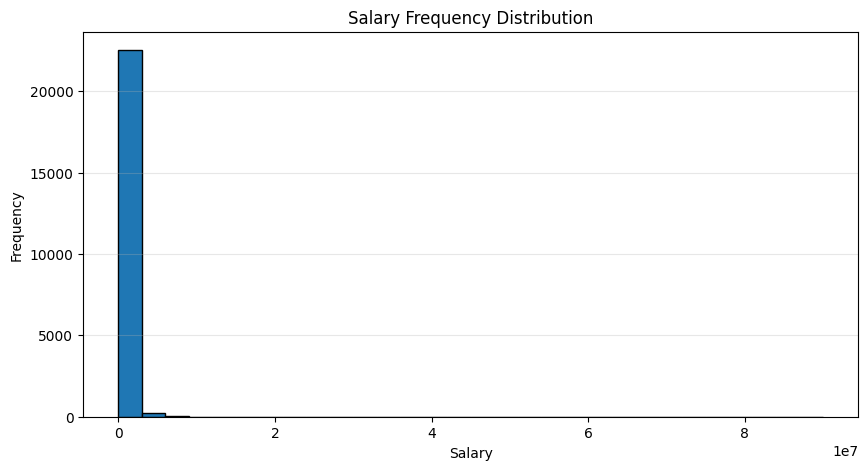

In [10]:
plt.figure(figsize=(10, 5))

plt.hist(
    df['Salary'].dropna(),
    bins=30,
    edgecolor='black'
)

plt.title('Salary Frequency Distribution')

plt.xlabel('Salary')

plt.ylabel('Frequency')

plt.grid(axis='y', alpha=0.3)

plt.show()

In [11]:
skewness = df['Salary'].skew()

print("Skewness:", skewness)

if skewness > 0.5:
    print("Distribution: Positively Skewed")

elif skewness < -0.5:
    print("Distribution: Negatively Skewed")

else:
    print("Distribution: Approximately Symmetrical")

Skewness: 46.79797994944103
Distribution: Positively Skewed


### Outlier Analysis

The salary distribution contains extreme values that affect
the visualisation and increase the mean and standard deviation.

Therefore, further analysis is required to understand the
impact of outliers on the salary distribution.

In [17]:
Q1 = df['Salary'].quantile(0.25)
Q3 = df['Salary'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['Salary'] < lower_limit) |
    (df['Salary'] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Number of Outliers:", len(outliers))

Lower Limit: -600000.0
Upper Limit: 1800000.0
Number of Outliers: 1156


## Practical Task 3 – Percentiles and Quartiles

In [12]:
percentiles = df['Salary'].quantile([
    0.10,
    0.25,
    0.50,
    0.75,
    0.90,
    0.95
])

print(percentiles)


0.10     180000.0
0.25     300000.0
0.50     500000.0
0.75     900000.0
0.90    1400000.0
0.95    1900000.0
Name: Salary, dtype: float64


In [13]:
Q1 = df['Salary'].quantile(0.25)

Q2 = df['Salary'].quantile(0.50)

Q3 = df['Salary'].quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)

print("Q2:", Q2)

print("Q3:", Q3)

print("IQR:", IQR)

Q1: 300000.0
Q2: 500000.0
Q3: 900000.0
IQR: 600000.0


## Practical Task 4 – Compare Two Groups Using Box Plots

In [14]:
print(df['Employment Status'].value_counts())

Employment Status
Full Time     20083
Intern         2106
Contractor      548
Trainee          33
Name: count, dtype: int64


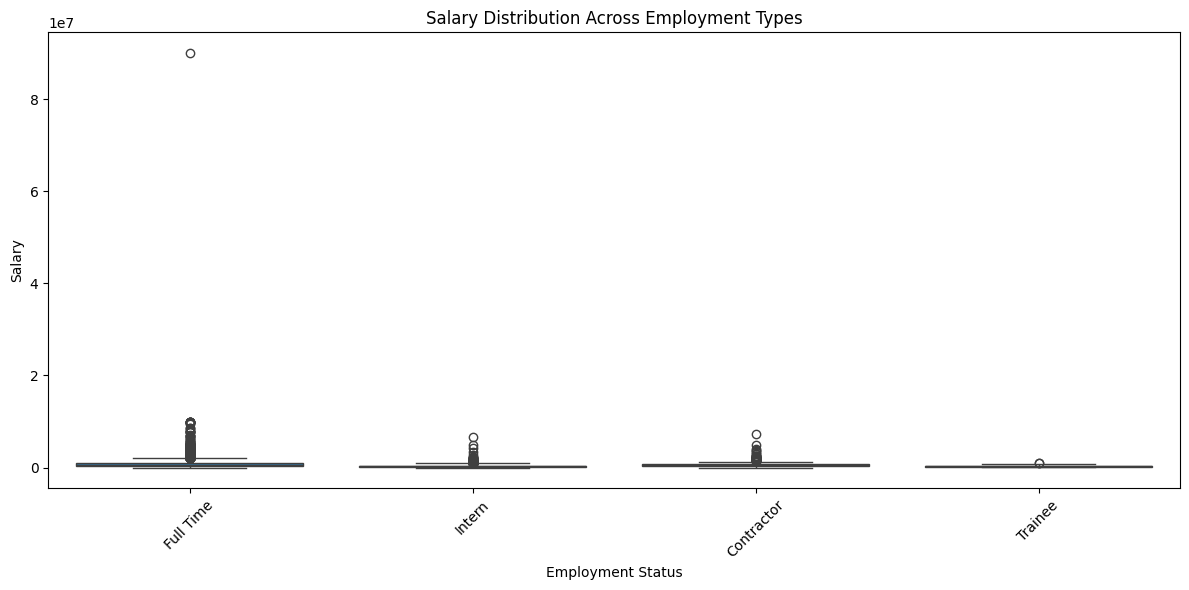

In [15]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='Employment Status',
    y='Salary'
)

plt.title('Salary Distribution Across Employment Types')

plt.xlabel('Employment Status')

plt.ylabel('Salary')

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

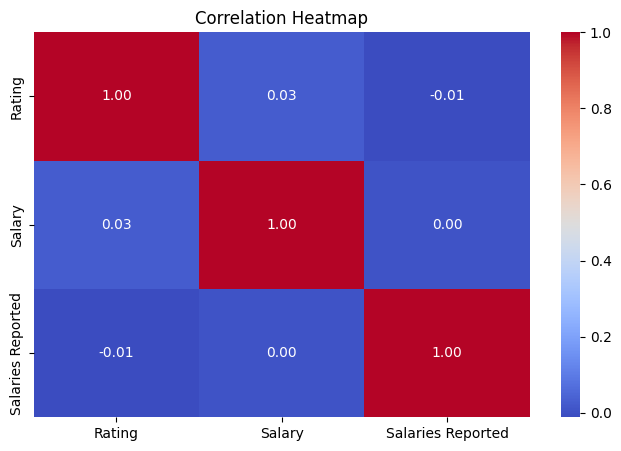

In [16]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

# Business Insights

Based on the descriptive statistical analysis of the Software Professional Salaries dataset, the following insights were identified:

1. **Salary Distribution:** The mean salary is higher than the median salary, indicating a positively skewed distribution.

2. **Salary Variation:** The standard deviation indicates considerable variation in salaries across the dataset.

3. **Most Common Salary:** The mode represents the most frequently occurring salary value.

4. **Outlier Detection:** Extreme salary observations were identified using the Interquartile Range (IQR) method.

5. **Employment Comparison:** Box plots help compare salary distributions across Full-Time, Intern, Contractor and Trainee employment categories.

6. **Correlation Analysis:** The correlation heatmap helps identify relationships between numerical variables such as rating, salary and salaries reported.

## Conclusion

This analysis provided practical experience in descriptive statistics using Python. I learned how to calculate statistical measures, interpret distributions, identify outliers, calculate percentiles and quartiles, and visualise data using histograms, box plots and correlation heatmaps.

These techniques are useful for understanding business data and supporting data-driven decision-making.
